In [2]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [4]:
IMG_SIZE = (256, 256)

def load_and_preprocess_image(image_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    image = (image - 127.5) / 127.5
    image = tf.expand_dims(image, axis=0)
    return image

In [5]:
generator_A2B = tf.keras.models.load_model('generator_A2B_model.keras')
generator_B2A = tf.keras.models.load_model('generator_B2A_model.keras')

I0000 00:00:1783267712.346464   58530 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 7106 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1070, pci bus id: 0000:01:00.0, compute capability: 6.1


In [7]:
IMAGE_PATH = 'image.jpg'
input_image = load_and_preprocess_image(IMAGE_PATH)

In [8]:
def deprocess_image(image):
    image = (image * 0.5) + 0.5
    return np.squeeze(image)

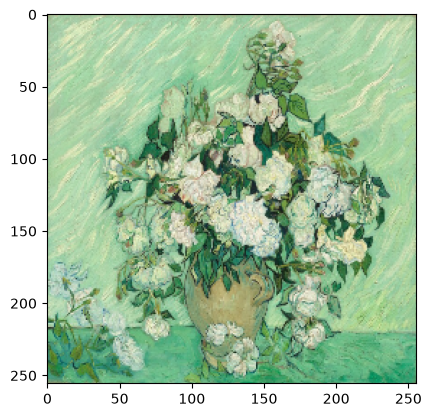

In [9]:
plt.imshow(deprocess_image(input_image))
plt.show()

In [10]:
translated_to_real = generator_A2B(input_image, training=False)
translated_to_vangogh = generator_B2A(input_image, training=False)

I0000 00:00:1783268083.937269   58530 cuda_dnn.cc:529] Loaded cuDNN version 90300


In [11]:
original_display = deprocess_image(input_image)
real_display = deprocess_image(translated_to_real)
vangogh_display = deprocess_image(translated_to_vangogh)

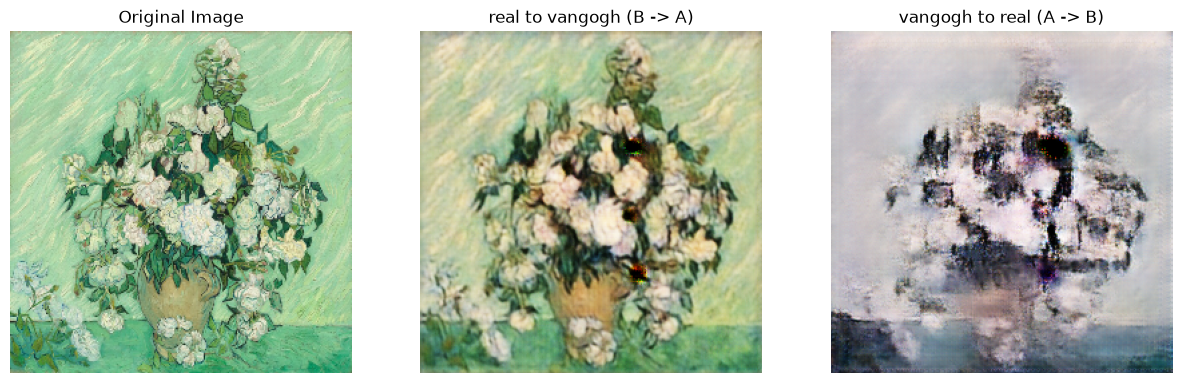

In [12]:
plt.figure(figsize=(15, 6))

plt.subplot(1, 3, 1)
plt.title("Original Image")
plt.imshow(original_display)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("real to vangogh (B -> A)")
plt.imshow(vangogh_display)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("vangogh to real (A -> B)")
plt.imshow(real_display)
plt.axis('off')

plt.show()